In [33]:
# 그래프 관련
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np

# 머신러닝 관련
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier  #평균절대값오차
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso

In [34]:
## 다중회귀 - 특성이 여러 개일 때
df = pd.read_csv('data/perch_full.csv')
df.head(3)

,length,height,width
0,8.4,2.11,1.41
1,13.7,3.53,2.00
2,15.0,3.82,2.43


In [35]:
perch_weight = [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]

In [36]:
# 학습데이터 / 테스트 데이터 분리
train_data,test_data,train_label,test_label = train_test_split(df,perch_weight, random_state=42)
train_data[:2]

,length,height,width
8,19.6,5.14,3.04
17,22.0,5.88,3.52


In [37]:
poly = PolynomialFeatures(degree=2, include_bias=False)
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)
train_poly[:2]

array([[ 19.6   ,   5.14  ,   3.04  , 384.16  , 100.744 ,  59.584 ,
         26.4196,  15.6256,   9.2416],
       [ 22.    ,   5.88  ,   3.52  , 484.    , 129.36  ,  77.44  ,
         34.5744,  20.6976,  12.3904]])

In [38]:
print(poly.get_feature_names_out())

['length' ' height' ' width' 'length^2' 'length  height' 'length  width'
 ' height^2' ' height  width' ' width^2']


In [39]:
# StandartScaler 규제 정규화
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)
train_scaled[:2]

array([[-1.01339619, -1.01007487, -1.01952321, -0.9549757 , -0.9496784 ,
        -0.95745849, -0.93942079, -0.94342509, -0.94100107],
       [-0.73842893, -0.75254307, -0.74466913, -0.76472563, -0.7717585 ,
        -0.77238267, -0.7747325 , -0.77298293, -0.76716811]])

In [56]:
alpha_list = [0.001,0.01,0.1,1,10,100]
train_score = []
test_score = []

for alpha in alpha_list:
    lasso = Lasso(alpha=alpha)
    lasso.fit(train_scaled,train_label)
    score = lasso.score(train_scaled, train_label)
    score2 = lasso.score(test_scaled, test_label)
    train_score.append(score)
    test_score.append(score2)
print('완료')

완료


c:\Python31315\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.902820e+04, tolerance: 5.183e+02
  model = cd_fast.enet_coordinate_descent(
c:\Python31315\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.685690e+04, tolerance: 5.183e+02
  model = cd_fast.enet_coordinate_descent(
c:\Python31315\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.545601e+03, tolerance: 5.183e+02
  model 

In [49]:
train_score

[0.9887077130101652,
 0.9887057827818039,
 0.9889737410220835,
 0.986591255464559,
 0.9827254657543516,
 0.9021189412769899]

In [60]:
print(f'정확도:{score*100}%, {score2*100}%')

정확도:90.21189412769898%, 90.64571064580718%


In [61]:
print(np.sum(lasso.coef_))

248.65682967622615


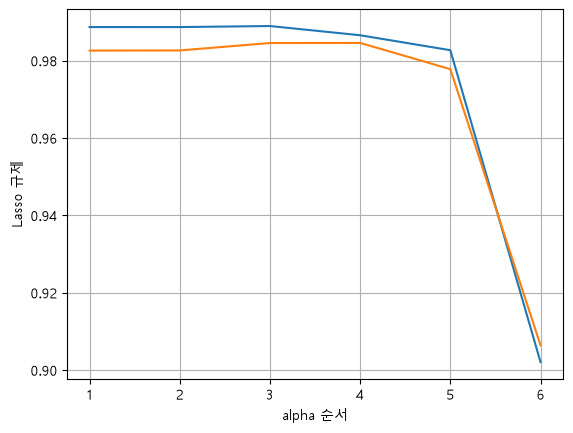

In [59]:
nlist = list(range(1,7))
plt.plot(nlist,train_score)
plt.plot(nlist,test_score)
plt.grid()
plt.xlabel('alpha 순서')
plt.ylabel('Lasso 규제')
plt.show()